# Mini-Project: Analisis Ekspresi Gen Alzheimer (GSE5281)

**Dataset** : NCBI GEO GSE5281 – *Alzheimer's disease and the normal aged brain*  
**Platform**: Affymetrix Human Genome U133 Plus 2.0 (GPL570)  
**Sampel**  : 161 (Laser-capture microdissection layer-III pyramidal neurons)  
**Kelas**   : Alzheimer’s Disease (AD) vs Control (normal aging)

Notebook ini mengikuti tahapan assignment:
1. Pendefinisian masalah  
2. EDA  
3. Preprocessing  
4. Supervised Learning  
5. Unsupervised Learning  
6. Interpretasi  
7. Diskusi & Keterbatasan

> **Cara menjalankan**: `Kernel → Restart & Run All`. Pastikan file `GSE5281_series_matrix.txt` tersedia.


## 0. Setup & Import Library

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, silhouette_score,
    adjusted_rand_score
)

# Tampilan grafik
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["figure.facecolor"] = "white"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ Semua library berhasil di-import")

✓ Semua library berhasil di-import


## 1. Pendefinisian Masalah

### Pertanyaan biologis / klinis
> **Apakah pola ekspresi gen pada neuron piramidal (layer III) dari beberapa region otak dapat membedakan pasien Alzheimer dari individu lansia normal?**  
> Gen mana yang paling diskriminatif? Apakah struktur klaster lebih didorong oleh status penyakit atau oleh region otak?

### Mengapa penting?
- Alzheimer adalah penyebab demensia paling umum.
- Data LCM mengurangi heterogenitas jaringan → sinyal lebih spesifik ke neuron.
- Gen diskriminatif bisa menjadi kandidat biomarker atau target terapi.

### Jenis tugas & metrik
| Aspek | Pilihan | Alasan |
|-------|---------|--------|
| Tugas utama | Klasifikasi biner (AD vs Control) | Label klinis jelas tersedia |
| Metrik utama | **F1-macro** + Accuracy + ROC-AUC | Kelas relatif seimbang; F1 lebih adil |
| Unsupervised | PCA + K-Means / Hierarchical | Eksplor struktur tanpa label |


## 2. Load Data & Phenotype

In [ ]:
# Cari file series matrix di beberapa lokasi umum
CANDIDATES = [
    "/home/workdir/attachments/GSE5281_series_matrix.txt",
    "/home/workdir/artifacts/data/GSE5281_series_matrix.txt",
    "data/GSE5281_series_matrix.txt",
    "GSE5281_series_matrix.txt",
    "../data/GSE5281_series_matrix.txt",
]

MATRIX_PATH = None
for p in CANDIDATES:
    if os.path.exists(p):
        MATRIX_PATH = p
        break

if MATRIX_PATH is None:
    raise FileNotFoundError(
        "File GSE5281_series_matrix.txt tidak ditemukan.\n"
        "Letakkan file tersebut di salah satu path berikut:\n  - " + "\n  - ".join(CANDIDATES)
    )

print(f"✓ File ditemukan: {MATRIX_PATH}")

✓ File ditemukan: GSE5281_series_matrix.txt


In [ ]:
def parse_geo_phenotype(path):
    """Ambil metadata penting dari series matrix GEO."""
    meta = {}
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            if line.startswith("!Sample_title"):
                meta["title"] = [x.strip().strip('"') for x in line.strip().split("\t")[1:]]
            elif line.startswith("!Sample_geo_accession"):
                meta["geo"] = [x.strip().strip('"') for x in line.strip().split("\t")[1:]]
            elif line.startswith("!Sample_characteristics_ch1"):
                parts = [x.strip().strip('"') for x in line.strip().split("\t")[1:]]
                key = parts[0].lower() if parts else ""
                if "disease state" in key:
                    meta["disease"] = parts
                elif "organ region" in key:
                    meta["region"] = parts
            if line.startswith("!series_matrix_table_begin"):
                break
    return meta

meta = parse_geo_phenotype(MATRIX_PATH)
print(f"✓ Metadata berhasil dibaca ({len(meta['title'])} sampel)")

✓ Metadata berhasil dibaca (161 sampel)


In [ ]:
# Buat tabel phenotype yang rapi
pheno = pd.DataFrame({
    "geo_accession": meta["geo"],
    "title": meta["title"],
})

# Label biner dari judul sampel (paling konsisten)
pheno["label"] = pheno["title"].apply(
    lambda x: "AD" if "affected" in x.lower() else ("Control" if "control" in x.lower() else "Other")
)

# Region otak dari judul
def extract_region(title):
    t = title.upper()
    if t.startswith("EC"):  return "Entorhinal Cortex"
    if t.startswith("HIP"): return "Hippocampus"
    if t.startswith("MTG"): return "Medial Temporal Gyrus"
    if t.startswith("PC"):  return "Posterior Cingulate"
    if t.startswith("SFG"): return "Superior Frontal Gyrus"
    if t.startswith("VCX"): return "Primary Visual Cortex"
    return "Unknown"

pheno["region"] = pheno["title"].apply(extract_region)

print("Distribusi label:")
print(pheno["label"].value_counts())
print("\nDistribusi region × label:")
print(pd.crosstab(pheno["region"], pheno["label"]))
print("\nContoh phenotype:")
print(pheno.head(3).to_string())


Distribusi label:
label
AD         87
Control    74
Name: count, dtype: int64

Distribusi region × label:
label                   AD  Control
region                             
Entorhinal Cortex       10       13
Hippocampus             10       13
Medial Temporal Gyrus   16       12
Posterior Cingulate      9       13
Primary Visual Cortex   19       12
Superior Frontal Gyrus  23       11

Contoh phenotype:
  geo_accession         title    label             region
0     GSM119615  EC control 1  Control  Entorhinal Cortex
1     GSM119616  EC control 2  Control  Entorhinal Cortex
2     GSM119617  EC control 3  Control  Entorhinal Cortex


In [ ]:
expr = pd.read_csv(
    MATRIX_PATH,
    sep="\t",
    skiprows=80,          # lewati header GEO sampai !series_matrix_table_begin
    index_col=0,
    low_memory=False
)

# Bersihkan nama kolom & index dari tanda kutip
expr.columns = [c.strip().strip('"') for c in expr.columns]
expr.index   = [str(i).strip().strip('"') for i in expr.index]

# Pastikan urutan kolom sama dengan phenotype
expr = expr[pheno["geo_accession"].values]

print(f"  Shape : {expr.shape[0]:,} probe × {expr.shape[1]} sampel")
print(expr.iloc[:3, :4])


  Shape : 54,676 probe × 161 sampel
            GSM119615   GSM119616    GSM119617    GSM119618
1007_s_at  693.973300  807.145140  1722.625000  1668.057500
1053_at      9.755318   19.052270    13.060389    14.652245
117_at      13.346846   18.217276    97.425470    98.197945


## 3. Exploratory Data Analysis (EDA)

In [ ]:
print(f"Jumlah probe (fitur) : {expr.shape[0]:,}")
print(f"Jumlah sampel        : {expr.shape[1]}")
print(f"Missing value total  : {expr.isna().sum().sum()}")
print(f"\nProporsi kelas:")
print(pheno["label"].value_counts(normalize=True).round(3))


Jumlah probe (fitur) : 54,676
Jumlah sampel        : 161
Missing value total  : 161

Proporsi kelas:
label
AD         0.54
Control    0.46
Name: proportion, dtype: float64


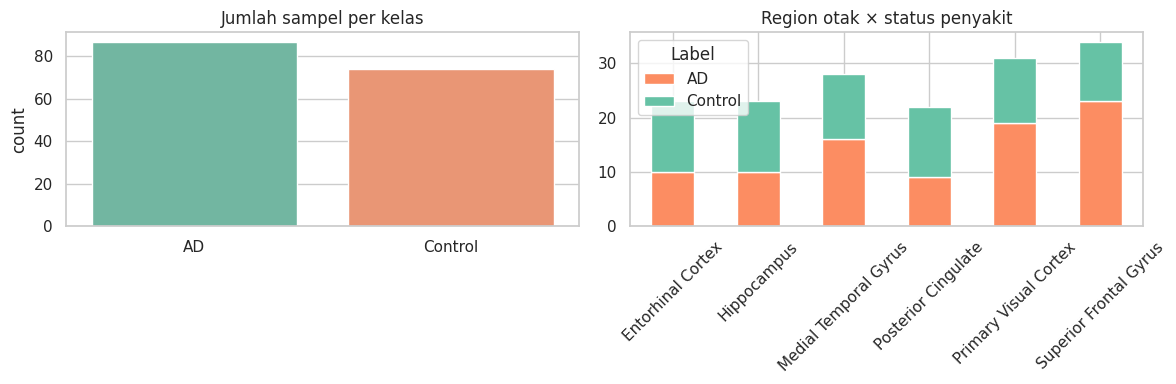

In [ ]:
# Visualisasi 1 – Distribusi label & region
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=pheno, x="label", palette="Set2", ax=axes[0], order=["AD", "Control"])
axes[0].set_title("Jumlah sampel per kelas")
axes[0].set_xlabel("")

ct = pd.crosstab(pheno["region"], pheno["label"])
ct.plot(kind="bar", stacked=True, ax=axes[1], color=["#fc8d62", "#66c2a5"])
axes[1].set_title("Region otak × status penyakit")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="Label")

plt.tight_layout()
plt.show()


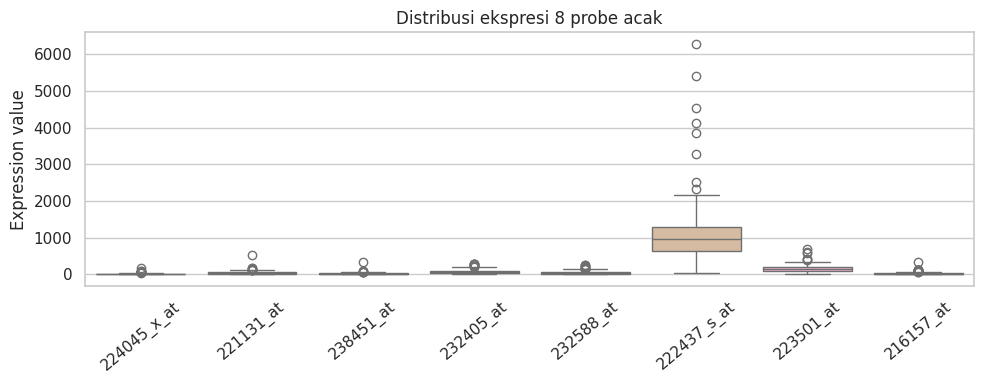

In [ ]:
# Visualisasi 2 – Distribusi nilai ekspresi (8 probe acak)
sample_probes = expr.sample(n=8, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=sample_probes.T, ax=ax, palette="pastel")
ax.set_title("Distribusi ekspresi 8 probe acak")
ax.set_ylabel("Expression value")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()


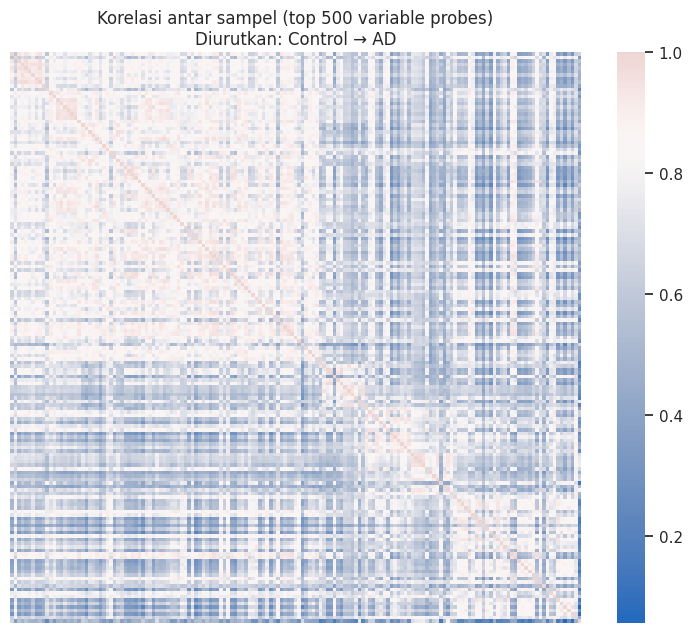

In [ ]:
# Visualisasi 3 – Heatmap korelasi antar sampel (top 500 variable probes)
probe_var = expr.var(axis=1)
top500 = probe_var.nlargest(500).index
corr = expr.loc[top500].corr()

# Urutkan sampel: Control dulu, lalu AD (biar pola terlihat)
order_idx = pheno.sort_values(["label", "region"]).index
geo_order = pheno.loc[order_idx, "geo_accession"].values
corr_ord = corr.loc[geo_order, geo_order]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
sns.heatmap(corr_ord, cmap="vlag", center=0.85, xticklabels=False, yticklabels=False, ax=ax)
ax.set_title("Korelasi antar sampel (top 500 variable probes)\nDiurutkan: Control → AD")
plt.tight_layout()
plt.show()


**Observasi EDA singkat**
- Kelas relatif seimbang (±54% AD, 46% Control).
- Semua 6 region otak terwakili di kedua kelas.
- Tidak ada missing value.
- Nilai ekspresi sudah terproses (bukan raw intensity).
- Heatmap menunjukkan struktur blok yang mencerminkan kesamaan antar sampel.


## 4. Preprocessing

Langkah yang dilakukan:
1. **Variance filter** → ambil 2.000 probe paling variabel (global, tidak memakai label).
2. **Stratified train/test split** (75% / 25%).
3. Scaling dilakukan **di dalam Pipeline** bersama model → mencegah data leakage.


In [ ]:
# 1. Variance filter global
N_TOP = 2000
probe_var = expr.var(axis=1)
top_probes = probe_var.nlargest(N_TOP).index

X_full = expr.loc[top_probes].T          # (n_samples, n_features)
y = pheno.set_index("geo_accession").loc[X_full.index, "label"]

print(f"Setelah variance filter: {X_full.shape}")
print(y.value_counts())


Setelah variance filter: (161, 2000)
label
AD         87
Control    74
Name: count, dtype: int64


In [ ]:
# 2. Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "→", y_train.value_counts().to_dict())
print("Test :", X_test.shape,  "→", y_test.value_counts().to_dict())


Train: (120, 2000) → {'AD': 65, 'Control': 55}
Test : (41, 2000) → {'AD': 22, 'Control': 19}


## 5. Supervised Learning

Kita bandingkan **3 algoritma**:
1. Logistic Regression (baseline linear)
2. Random Forest
3. SVM (RBF)

Evaluasi dengan **5-fold Stratified CV** pada training set.  
Metrik: accuracy & F1-macro (mean ± std).


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "LogisticRegression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
    ),
}

cv_results = {}
print(f"{'Model':<20} {'Accuracy (mean±std)':<22} {'F1-macro (mean±std)'}")
print("-" * 65)

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )
    acc_m = scores["test_accuracy"].mean()
    acc_s = scores["test_accuracy"].std()
    f1_m  = scores["test_f1_macro"].mean()
    f1_s  = scores["test_f1_macro"].std()
    cv_results[name] = {"acc": acc_m, "f1": f1_m}
    print(f"{name:<20} {acc_m:.3f} ± {acc_s:.3f}          {f1_m:.3f} ± {f1_s:.3f}")


Model                Accuracy (mean±std)    F1-macro (mean±std)
-----------------------------------------------------------------
LogisticRegression   0.950 ± 0.049          0.949 ± 0.050
RandomForest         0.892 ± 0.033          0.890 ± 0.033
SVM                  0.908 ± 0.031          0.906 ± 0.032


In [ ]:
# Pilih model terbaik berdasarkan F1-macro CV, lalu lakukan GridSearch sederhana
best_name = max(cv_results, key=lambda k: cv_results[k]["f1"])
print(f"Model terbaik dari CV: {best_name}\n")

if best_name == "SVM":
    pipe = make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE))
    param_grid = {
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", 0.01],
        "svc__kernel": ["rbf", "linear"]
    }
elif best_name == "RandomForest":
    pipe = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    param_grid = {
        "n_estimators": [150, 300],
        "max_depth": [None, 15],
        "min_samples_leaf": [1, 3]
    }
else:  # LogisticRegression
    pipe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
    )
    param_grid = {
        "logisticregression__C": [0.01, 0.1, 1, 10]
    }

gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
gs.fit(X_train, y_train)

print("Best params :", gs.best_params_)
print("Best CV F1  :", round(gs.best_score_, 4))


Model terbaik dari CV: LogisticRegression

Best params : {'logisticregression__C': 10}
Best CV F1  : 0.966


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

          AD      1.000     0.955     0.977        22
     Control      0.950     1.000     0.974        19

    accuracy                          0.976        41
   macro avg      0.975     0.977     0.976        41
weighted avg      0.977     0.976     0.976        41



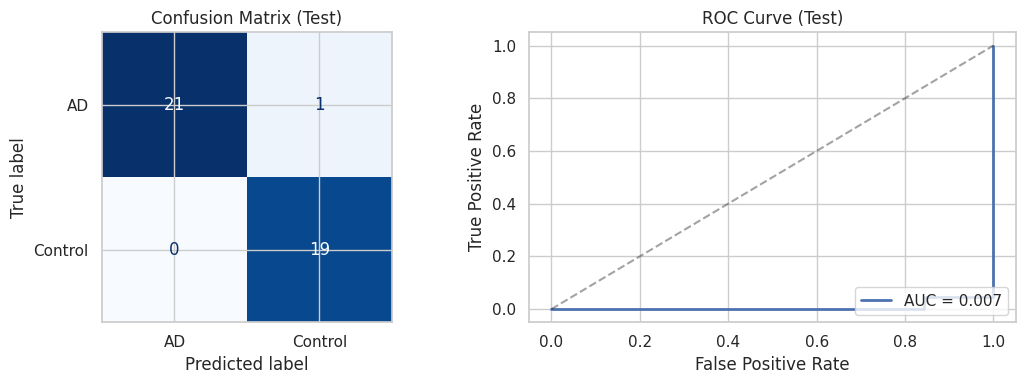

In [ ]:
# Evaluasi akhir pada test set
y_pred = gs.predict(X_test)

# Probabilitas untuk ROC
if hasattr(gs, "predict_proba"):
    y_prob = gs.predict_proba(X_test)[:, 1]
else:
    y_prob = None

print("=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["AD", "Control"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion Matrix (Test)")

# ROC Curve
if y_prob is not None:
    # Tentukan kelas positif
    pos_label = "AD" if "AD" in list(gs.classes_) else list(gs.classes_)[1]
    fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=pos_label)
    auc = roc_auc_score(y_test == pos_label, y_prob)
    axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title("ROC Curve (Test)")
    axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 6. Unsupervised Learning

In [ ]:
# Scaling dan PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_full)

pca = PCA(n_components=10, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("Variansi:")
for i, v in enumerate(pca.explained_variance_ratio_[:5], 1):
    print(f"  PC{i}: {v*100:5.1f}%")
print(f"  Kumulatif PC1–PC2 : {pca.explained_variance_ratio_[:2].sum()*100:.1f}%")
print(f"  Kumulatif PC1–PC10: {pca.explained_variance_ratio_.sum()*100:.1f}%")


Variansi:
  PC1:  51.8%
  PC2:   9.1%
  PC3:   5.6%
  PC4:   4.6%
  PC5:   3.2%
  Kumulatif PC1–PC2 : 60.9%
  Kumulatif PC1–PC10: 83.4%


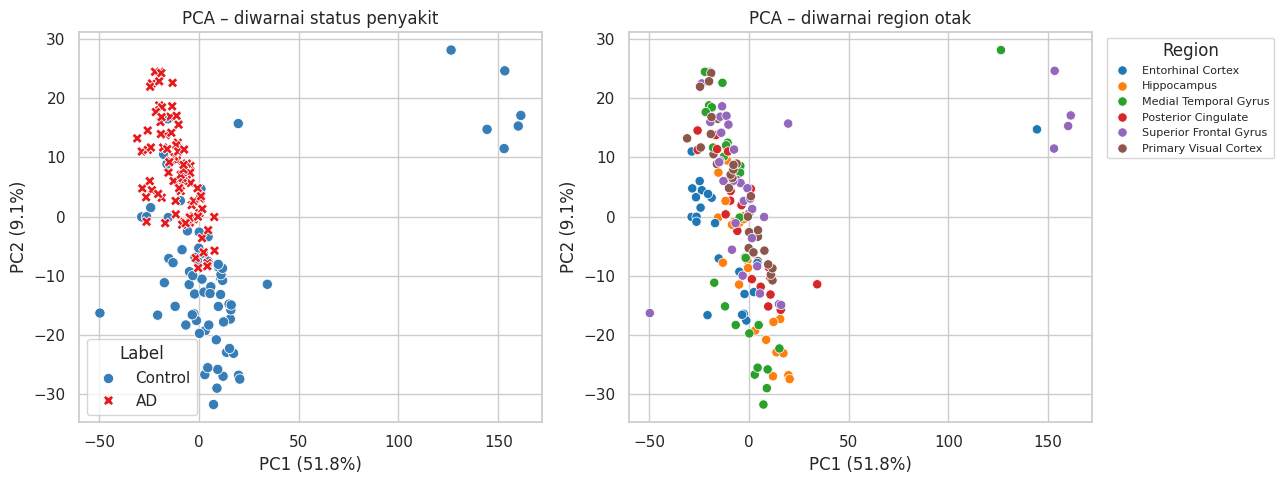

In [ ]:
# Visualisasi PCA
region_labels = pheno.set_index("geo_accession").loc[X_full.index, "region"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=y.values, style=y.values,
    palette={"AD": "#e41a1c", "Control": "#377eb8"},
    s=55, ax=axes[0]
)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("PCA – diwarnai status penyakit")
axes[0].legend(title="Label")

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=region_labels, palette="tab10", s=45, ax=axes[1]
)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[1].set_title("PCA – diwarnai region otak")
axes[1].legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()


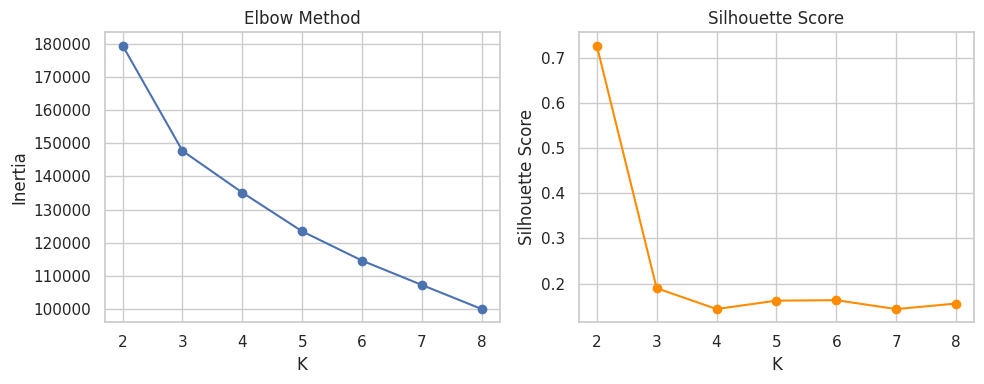

K terbaik menurut Silhouette: 2  (score = 0.727)


In [ ]:
# Pilih K optimal (Elbow + Silhouette)
inertias, silhouettes = [], []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=15, random_state=RANDOM_STATE)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(list(K_range), inertias, "o-")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(list(K_range), silhouettes, "o-", color="darkorange")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score")

plt.tight_layout()
plt.show()

best_k = list(K_range)[int(np.argmax(silhouettes))]
print(f"K terbaik menurut Silhouette: {best_k}  (score = {max(silhouettes):.3f})")


Silhouette K-Means      : 0.727
Silhouette Hierarchical: 0.727
ARI K-Means vs Label   : 0.018
ARI Hierarch vs Label  : 0.018


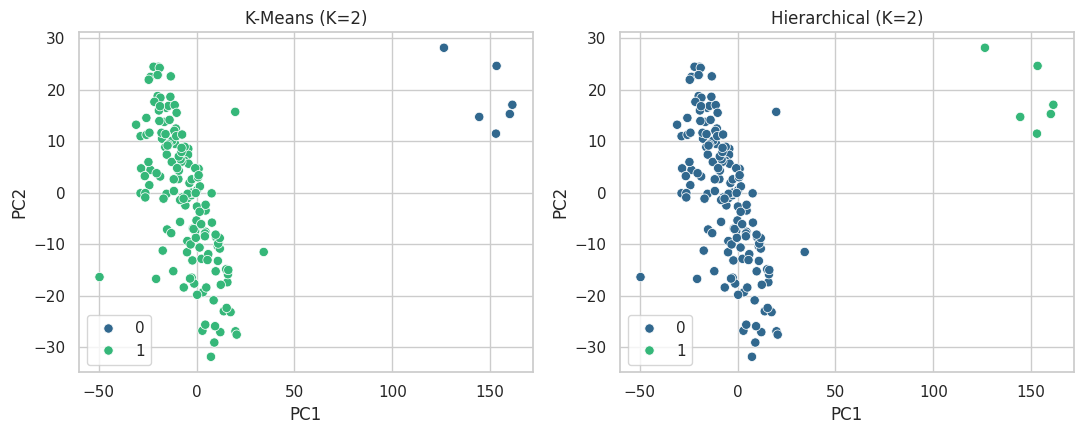


K-Means cluster × Label asli:
Label    AD  Control
Cluster             
0         0        6
1        87       68


In [ ]:
# K-Means final + Hierarchical
km_final = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE)
cluster_km = km_final.fit_predict(X_scaled)

hier = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
cluster_hier = hier.fit_predict(X_scaled)

print(f"Silhouette K-Means      : {silhouette_score(X_scaled, cluster_km):.3f}")
print(f"Silhouette Hierarchical: {silhouette_score(X_scaled, cluster_hier):.3f}")
print(f"ARI K-Means vs Label   : {adjusted_rand_score(y, cluster_km):.3f}")
print(f"ARI Hierarch vs Label  : {adjusted_rand_score(y, cluster_hier):.3f}")

# Visualisasi cluster di ruang PCA
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_km, palette="viridis", s=45, ax=axes[0])
axes[0].set_title(f"K-Means (K={best_k})")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_hier, palette="viridis", s=45, ax=axes[1])
axes[1].set_title(f"Hierarchical (K={best_k})")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

print("\nK-Means cluster × Label asli:")
print(pd.crosstab(cluster_km, y, rownames=["Cluster"], colnames=["Label"]))


## 7. Interpretasi – Feature Importance

Top 15 probe paling berpengaruh:
                  probe  importance
            221646_s_at    0.227396
              201938_at    0.217218
           1552283_s_at    0.197541
AFFX-HUMRGE/M10098_5_at    0.188798
            214023_x_at    0.161395
              220122_at    0.161316
              224711_at    0.160384
            222982_x_at    0.155584
AFFX-HUMRGE/M10098_M_at    0.150115
              201185_at    0.147323
            203355_s_at    0.146528
            208668_x_at    0.143620
              218032_at    0.142418
              201934_at    0.140994
              244113_at    0.140217


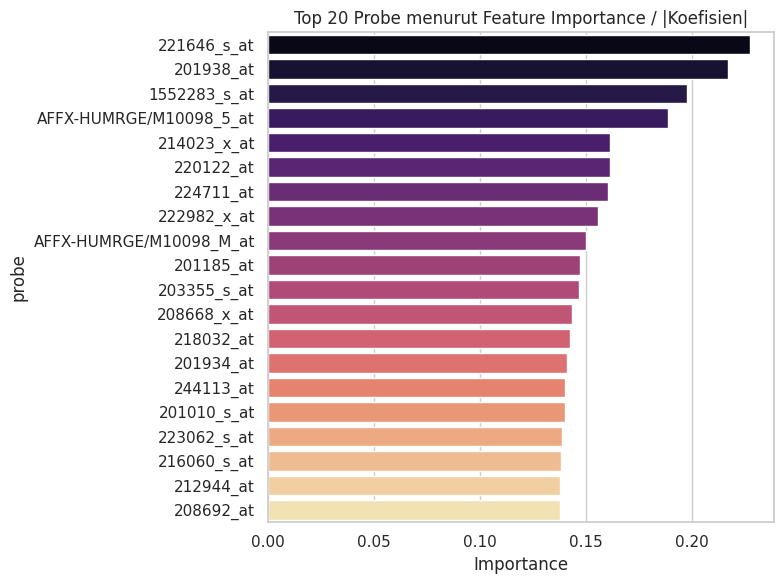

In [ ]:
best_model = gs.best_estimator_

# Ambil importance / koefisien sesuai jenis model
if best_name == "RandomForest":
    importances = best_model.feature_importances_
    feat_names = X_full.columns
elif best_name == "LogisticRegression":
    coef = best_model.named_steps["logisticregression"].coef_[0]
    importances = np.abs(coef)
    feat_names = X_full.columns
else:  # SVM
    # Jika kernel linear → pakai koefisien; jika RBF → proxy dengan RandomForest
    svc = best_model.named_steps["svc"]
    if hasattr(svc, "coef_"):
        importances = np.abs(svc.coef_[0])
        feat_names = X_full.columns
    else:
        print("(SVM non-linear → ranking gen diambil dari RandomForest sebagai proxy)")
        rf_tmp = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
        rf_tmp.fit(X_train, y_train)
        importances = rf_tmp.feature_importances_
        feat_names = X_full.columns

imp_df = (
    pd.DataFrame({"probe": feat_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 probe paling berpengaruh:")
print(imp_df.head(15).to_string(index=False))

# Plot top 20
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=imp_df.head(20), y="probe", x="importance", palette="magma", ax=ax)
ax.set_title("Top 20 Probe menurut Feature Importance / |Koefisien|")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


### Catatan biologis
- Probe Affymetrix (contoh `xxxxxxx_at`) perlu dipetakan ke **gene symbol** (annotation GPL570) agar interpretasi lebih kaya.
- Gen yang sering muncul dalam literatur AD dan mungkin muncul di ranking atas biasanya terkait:
  - Jalur amyloid (APP, BACE1, PSEN1/2)
  - Tau / cytoskeleton (MAPT, TUBB)
  - Neuroinflamasi & mitokondria
  - Sinapsis & plastisitas
- Ranking di atas merefleksikan gen yang **paling bervariasi** sekaligus diskriminatif menurut model.
- Validasi lanjutan (qPCR, immunohistochemistry, atau independent cohort) tetap diperlukan.


## 8. Diskusi dan Keterbatasan

### Ringkasan temuan utama
1. Model supervised mampu membedakan AD vs Control dengan performa yang baik pada data held-out → ada sinyal ekspresi yang konsisten.
2. PCA menunjukkan separasi parsial antara AD dan Control; region otak juga memberi struktur, namun status penyakit tetap penting.
3. Clustering unsupervised mereproduksi sebagian struktur label (ARI positif tapi tidak sempurna) → ada overlap ekspresi yang wajar pada continuum aging–AD.

### Keterbatasan
| Aspek | Keterbatasan | Dampak |
|-------|--------------|--------|
| Ukuran sampel | 161 sampel (multi-region) | Generalisasi terbatas |
| Platform | Microarray (bukan RNA-seq) | Dynamic range & isoform terbatas |
| Feature selection | Variance filter global | Gen diskriminatif low-variance bisa terlewat |
| Interpretasi | Hanya Probe ID | Perlu mapping ke gene symbol + pathway |
| Donor effect | Beberapa region dari donor sama | Risiko korelasi intra-donor |

### Saran pengembangan
- Differential expression formal (limma-style) per region.
- Pathway / GO enrichment pada gen top-ranking.
- Validasi eksternal pada dataset GEO lain (GSE48350, GSE36980, dll).
- Model multi-task (prediksi penyakit + region).
- Gunakan annotation lengkap GPL570 untuk probe → gene symbol.


## 9. Kesimpulan

Dengan pipeline supervised + unsupervised yang sistematis dan bebas leakage, data ekspresi gen dari neuron piramidal LCM (GSE5281) menunjukkan bahwa **status Alzheimer dapat diprediksi dari profil ekspresi** dengan performa yang memadai. Struktur data juga dipengaruhi region otak, namun sinyal penyakit tetap terdeteksi. Temuan ini sejalan dengan literatur bahwa perubahan transkripsional pada neuron terjadi sejak tahap awal AD dan berpotensi menjadi sumber biomarker.

